# Notebook 14 — Explicabilidade e interpretabilidade (E26)

Análise completa sobre a receita de produção **E26** (F&H-5seed + relabel-15 +
`max(pred, FAIXA_MINIMA)`), combinando **pandas**, **scikit-learn** e **SHAP 0.52**.

**Contrato de explicação (SHAP skill, obrigações de reporte):**
- Modelo explicado: XGBoost multiclasse (receita nb11, treinado com rótulos *relabel*)
  ajustado na **fold 0 de treino**; linhas de explicação = **fold 0 de validação (held-out)**.
- Unidade: **margem bruta (raw margin / logit)** por classe — SHAP `TreeExplainer`
  padrão (tree-path-dependent, sem background externo).
- Verificação de aditividade: `base_values + Σ shap == booster.predict(output_margin=True)`.
- Comparabilidade: modelo com rótulos originais, mesmas linhas/mesma saída → estabilidade.
- Agregação: apenas **valores absolutos** entre classes (nunca médias de atribuições com sinal).
- Figuras: `docs/fig_nb14_*.png` (para o relatório de janeiro).
- **Não causal**: SHAP descreve o comportamento do modelo sob uma regra de masking;
  não estabelece causalidade, mecanismo nem fairness.

Modo rápido: `NB14_MODO=rapido` (menos linhas SHAP, menos repeats).

In [1]:
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (f1_score, classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
K = 16
TARGET = 'AGE_RANGE'
MODO = os.environ.get('NB14_MODO', 'completo')
RAPIDO = MODO in ('rapido', 'ecra')
N_REPEATS = 1 if RAPIDO else 3
FIG_DIR = 'docs' if os.path.isdir('docs') else os.path.join('..', 'docs')

def _data_dir():
    for cand in [os.path.join('..', '..', 'data'), os.path.join('..', 'data'), 'data']:
        if os.path.isdir(cand):
            return cand
    raise FileNotFoundError('pasta data/ nao encontrada')
DATA_DIR = _data_dir()

def fig(nome):
    """Caminho da figura + guarda o eixo atual."""
    p = os.path.join(FIG_DIR, f'fig_nb14_{nome}.png')
    plt.gca().figure.savefig(p, bbox_inches='tight')
    print('figura:', p)

RES = []
def reg(secao, metrica, valor, nota=''):
    RES.append({'secao': secao, 'metrica': metrica, 'valor': valor, 'nota': nota})
    print(f'[{secao}] {metrica}: {valor} {nota}')

print('MODO=', MODO, '| shap', shap.__version__, '| xgb', xgb.__version__)

MODO= completo | shap 0.52.0 | xgb 3.4.1


/home/rui/miniconda3/envs/daa/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dados, produção E26 (cache) e sanidade

In [2]:
tr = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'))
y = tr[TARGET].to_numpy().astype(int)
cols = [c for c in tr.columns if c not in ('PID', TARGET)]
X = tr[cols]
Xv = X.to_numpy(dtype=np.float64)
fmin = tr['FAIXA_MINIMA'].to_numpy().astype(int)
n = len(y)
FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=42).split(Xv, y))
b0, v0 = FOLDS[0]          # fold 0: treino / validação held-out para tudo o que explica

# rótulos relabel (E26): piores 15% ← OOF cross-fit do nb11
d11 = np.load(os.path.join(DATA_DIR, 'nb11_oof311.npz'))
oof_x, proba_x = d11['oof'].astype(int), d11['proba']
rank = np.argsort(proba_x[np.arange(n), y])
y_lab = y.copy()
rr = rank[:int(n * 0.15)]
y_lab[rr] = oof_x[rr]

# predições E26 (produção) a partir do cache do NB13
P13 = np.load(os.path.join(DATA_DIR, 'nb13_rel15_5seed.npz'))['Pall'].mean(axis=0)
pmax = P13.max(axis=1)
pred_raw = P13.argmax(axis=1)
pred_e26 = np.maximum(pred_raw, fmin)
folds_e26 = np.array([f1_score(y[va], pred_e26[va], average='macro') for _, va in FOLDS])
print('E26 folds:', np.round(folds_e26, 4).tolist(), 'mean=%.4f' % folds_e26.mean())
assert abs(folds_e26.mean() - 0.5364) < 0.001, 'cache E26 inesperado'
reg('sanidade', 'E26_mean_fold_f1', round(folds_e26.mean(), 4), 'cache NB13 rel15')

E26 folds: [0.5464, 0.546, 0.5324, 0.5284, 0.5288] mean=0.5364
[sanidade] E26_mean_fold_f1: 0.5364 cache NB13 rel15


## 2. Estrutura de erro e calibração (pandas + scikit-learn)

figura: ../docs/fig_nb14_confusao.png


,precision,recall,f1-score,support
0,0.814,0.932,0.869,207.000
1,0.556,0.436,0.489,172.000
2,0.642,0.674,0.658,399.000
3,0.471,0.515,0.492,377.000
4,0.383,0.403,0.393,449.000
5,0.419,0.450,0.434,647.000
6,0.443,0.413,0.427,859.000
7,0.445,0.447,0.446,862.000
8,0.703,0.654,0.678,905.000
9,0.687,0.724,0.705,1014.000


[erro] macro_f1: 0.5365 


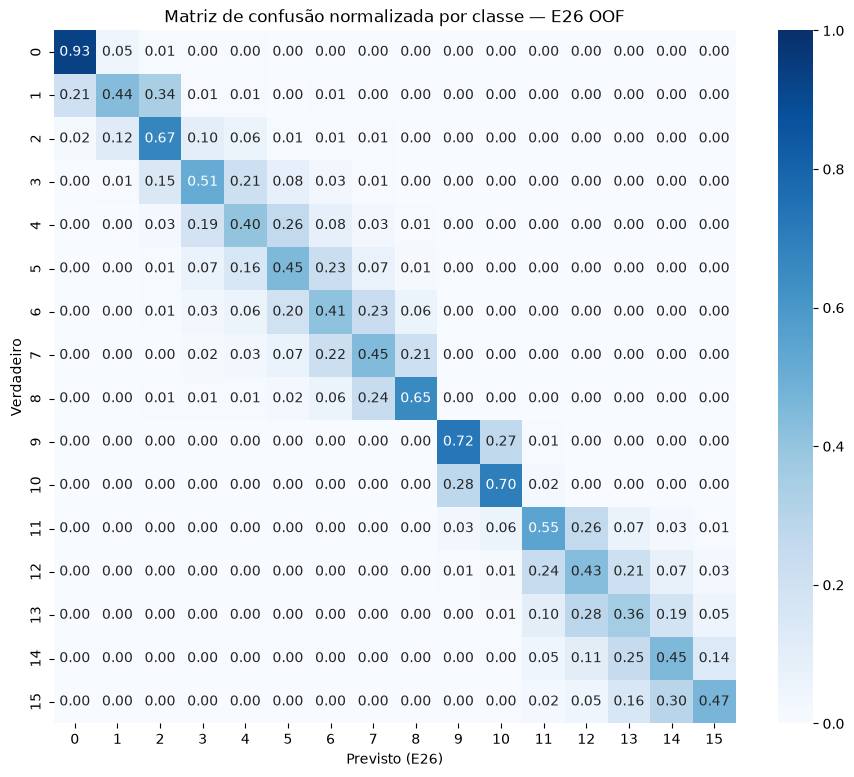

In [3]:
cm = confusion_matrix(y, pred_e26, normalize='true')
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            xticklabels=range(K), yticklabels=range(K))
plt.xlabel('Previsto (E26)'); plt.ylabel('Verdadeiro')
plt.title('Matriz de confusão normalizada por classe — E26 OOF')
fig('confusao')
rep = classification_report(y, pred_e26, output_dict=True, zero_division=0)
tab = pd.DataFrame(rep).T.round(3)
display(tab.head(17))
tab.to_csv(os.path.join(DATA_DIR, 'nb14_relatorio_por_classe.csv'))
reg('erro', 'macro_f1', round(f1_score(y, pred_e26, average='macro'), 4))

figura: ../docs/fig_nb14_erros.png
[erro] off_by_one_pct: 76.0 % dos erros são de 1 faixa
[erro] erro_ge2_n: 1229 
figura: ../docs/fig_nb14_calibracao.png
[calibracao] ECE_10bins: 0.0953 
[correcao] linhas_alteradas: 19 ajudou 10 / prejudicou 0


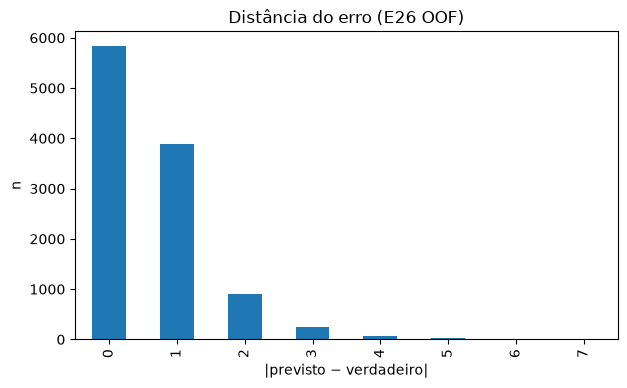

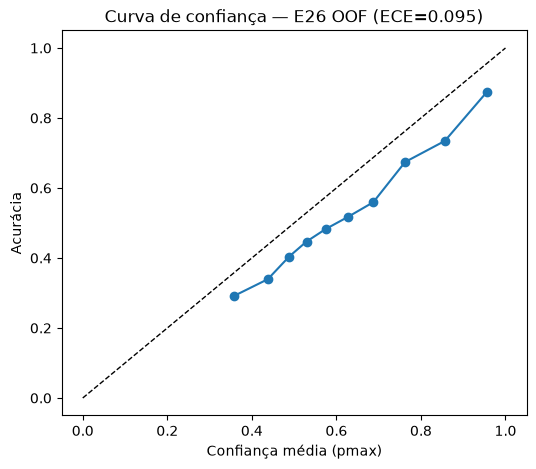

In [4]:
err = np.abs(pred_e26 - y)
plt.figure(figsize=(7, 4))
pd.Series(err).value_counts().sort_index().plot(kind='bar')
plt.xlabel('|previsto − verdadeiro|'); plt.ylabel('n')
plt.title('Distância do erro (E26 OOF)')
fig('erros')
reg('erro', 'off_by_one_pct', round(float((err == 1).sum() / (err > 0).sum() * 100), 1),
    '% dos erros são de 1 faixa')
reg('erro', 'erro_ge2_n', int((err >= 2).sum()))

# calibração: confiança (pmax) vs acerto, 10 bins + ECE
bins = pd.qcut(pmax, 10, labels=False, duplicates='drop')
cal = pd.DataFrame({'conf': pmax, 'ok': (pred_e26 == y).astype(float), 'bin': bins}).groupby('bin')
ece = float((cal.apply(lambda g: len(g) * abs(g['conf'].mean() - g['ok'].mean()))).sum() / n)
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.plot(cal['conf'].mean(), cal['ok'].mean(), 'o-')
plt.xlabel('Confiança média (pmax)'); plt.ylabel('Acurácia')
plt.title(f'Curva de confiança — E26 OOF (ECE={ece:.3f})')
fig('calibracao')
reg('calibracao', 'ECE_10bins', round(ece, 4))

# auditoria da correção FAIXA_MINIMA no OOF
mudou = pred_e26 != pred_raw
reg('correcao', 'linhas_alteradas', int(mudou.sum()),
    f'ajudou {int((pred_e26[mudou]==y[mudou]).sum())} / '
    f'prejudicou {int((pred_raw[mudou]==y[mudou]).sum())}')

## 3. Modelo de auditoria + efeito do relabel no multiclasse

XGBoost multiclasse (receita nb11) ajustado na fold-0 com rótulos **relabel** (`M0`)
e com rótulos **originais** (`M0_orig`) — mesma fold, mesmas linhas de validação,
para medir (a) CV do relabel no multiclasse e (b) estabilidade das explicações.

In [5]:
def xgb_recipe():
    return XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        tree_method='hist', random_state=42, n_jobs=-1, eval_metric='mlogloss')

def cv_relabel():
    p = os.path.join(DATA_DIR, 'nb14_cv_relabel.npz')
    if os.path.exists(p):
        return np.load(p)['f1s']
    f1s = []
    t0 = time.time()
    for fi, (a, b) in enumerate(FOLDS):
        m = xgb_recipe()
        m.fit(Xv[a], y_lab[a], sample_weight=compute_sample_weight('balanced', y_lab[a]))
        f1s.append(f1_score(y[b], m.predict(Xv[b]), average='macro'))
        print(f'  cv fold {fi}: {f1s[-1]:.4f} ({time.time()-t0:.0f}s)', flush=True)
    f1s = np.array(f1s)
    np.savez_compressed(p, f1s=f1s)
    return f1s

f1s_cv = cv_relabel()
reg('auditoria', 'cv_relabel_multiclasse', round(f1s_cv.mean(), 4),
    f'+/- {f1s_cv.std():.4f} | base original 0.4777 → delta {f1s_cv.mean()-0.4777:+.4f}')

M0 = xgb_recipe()
M0.fit(Xv[b0], y_lab[b0], sample_weight=compute_sample_weight('balanced', y_lab[b0]))
M0_orig = xgb_recipe()
M0_orig.fit(Xv[b0], y[b0], sample_weight=compute_sample_weight('balanced', y[b0]))
X_val, y_val = Xv[v0], y[v0]
print('M0 (relabel) val macro-F1:', round(f1_score(y_val, M0.predict(X_val), average='macro'), 4))
print('M0_orig      val macro-F1:', round(f1_score(y_val, M0_orig.predict(X_val), average='macro'), 4))

[auditoria] cv_relabel_multiclasse: 0.5341 +/- 0.0065 | base original 0.4777 → delta +0.0564


M0 (relabel) val macro-F1: 0.5426


M0_orig      val macro-F1: 0.4881


## 4. SHAP global (margem bruta, held-out fold 0)

M0_relabel: shap (2193, 311, 16) | aditividade max|erro| = 1.34e-05
[shap] aditividade_M0_relabel: 1.3e-05 base+Σshap == margem bruta
SHAP M0 em 2193 linhas held-out: 23s


figura: ../docs/fig_nb14_shap_global.png


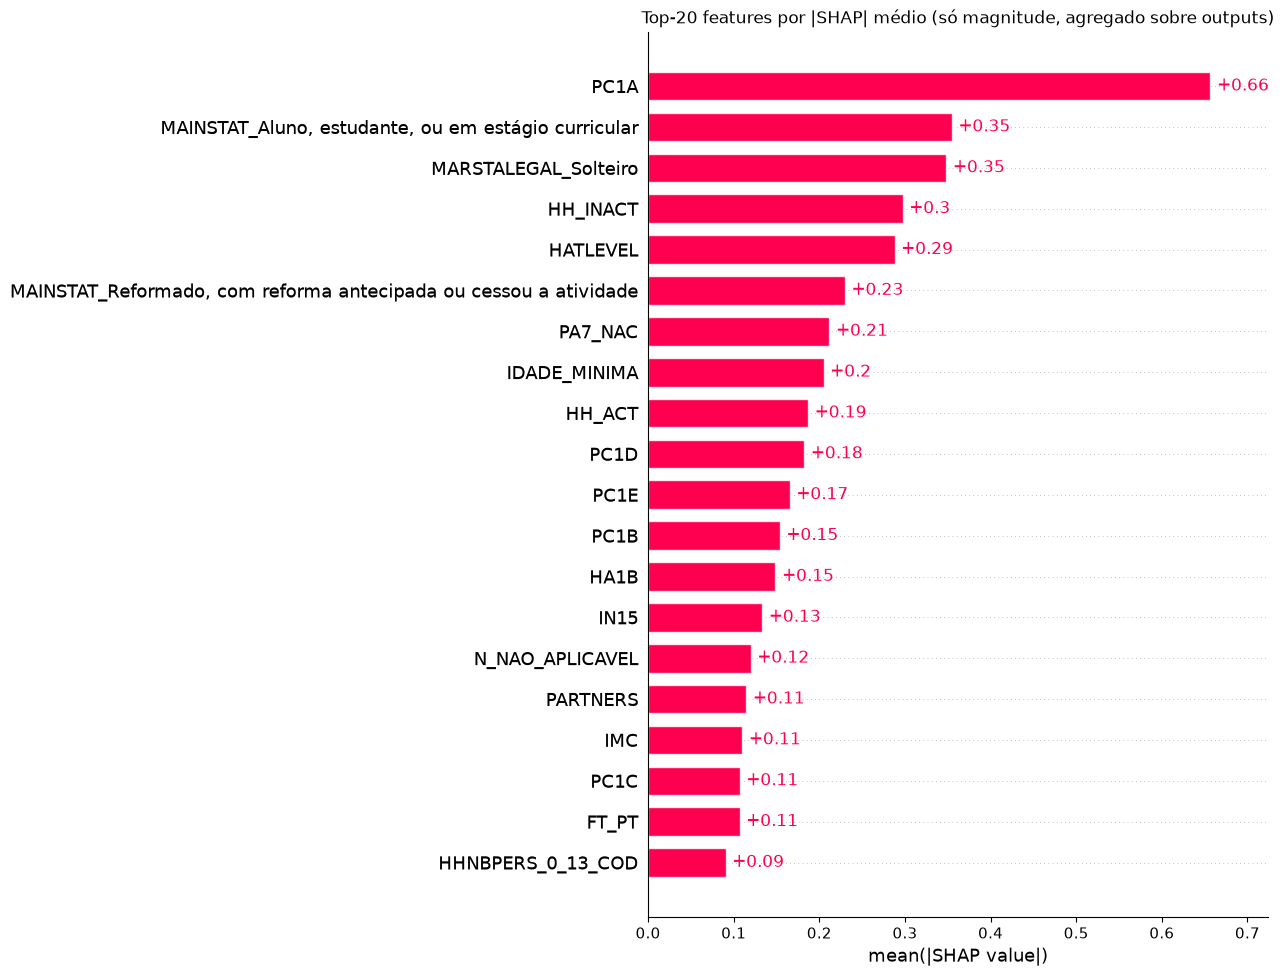

In [6]:
def shap_do(modelo, Xrows, tag):
    """SHAP 0.52: explainer(X) preferido; validação de aditividade obrigatória
    (base + Σshap == margem bruta do booster). Devolve Explanation 3D (multiclasse)
    ou 2D (binário)."""
    expl = shap.TreeExplainer(modelo)
    exp = expl(Xrows)                       # API moderna (preferida pela skill)
    sv = exp.values
    if isinstance(sv, list):
        sv = np.stack(sv, axis=-1)
    sv = np.asarray(sv)
    if sv.ndim == 2:                        # binário -> (n, f, 1)
        sv = sv[:, :, None]
    bv = np.asarray(exp.base_values)
    if bv.ndim == 0:
        bv = np.full((len(Xrows), 1), float(bv))
    elif bv.ndim == 1:
        bv = (bv.reshape(-1, 1) if bv.shape[0] == len(Xrows)
              else np.broadcast_to(bv, (len(Xrows), bv.shape[0])))
    elif bv.shape[0] != len(Xrows):
        bv = np.broadcast_to(bv, (len(Xrows), bv.shape[-1]))
    rec = bv + sv.sum(axis=1)
    marg = modelo.get_booster().predict(xgb.DMatrix(Xrows), output_margin=True)
    if marg.ndim == 1:
        marg = marg.reshape(-1, 1)
    assert rec.shape == marg.shape, (rec.shape, marg.shape)
    err = float(np.abs(rec - marg).max())
    print(f'{tag}: shap {sv.shape} | aditividade max|erro| = {err:.2e}')
    assert err < 1e-3, f'falha de aditividade {tag}: {err}'
    reg('shap', f'aditividade_{tag}', f'{err:.1e}', 'base+Σshap == margem bruta')
    if sv.shape[2] == 1:                    # binário -> Explanation 2D
        return shap.Explanation(values=sv[:, :, 0], base_values=bv[:, 0],
                                data=Xrows, feature_names=cols)
    return shap.Explanation(values=sv, base_values=bv, data=Xrows,
                            feature_names=cols)

t0 = time.time()
exp = shap_do(M0, X_val, 'M0_relabel')
print(f'SHAP M0 em {len(X_val)} linhas held-out: {time.time()-t0:.0f}s')

glob = np.abs(exp.values).mean(axis=(0, 2))   # só magnitudes (nunca médias com sinal)
ordem = np.argsort(-glob)
tab_glob = pd.DataFrame({'feature': np.array(cols)[ordem], 'mean_abs_shap': glob[ordem]})
g20 = np.abs(exp.values[:, ordem[:20], :]).mean(axis=2)
shap.plots.bar(shap.Explanation(values=g20,
                                feature_names=np.array(cols)[ordem[:20]]),
               max_display=20, show=False)
plt.title('Top-20 features por |SHAP| médio (só magnitude, agregado sobre outputs)')
fig('shap_global')

figura: ../docs/fig_nb14_shap_beeswarm_classe_13.png


figura: ../docs/fig_nb14_shap_beeswarm_classe_1.png


figura: ../docs/fig_nb14_shap_heatmap_classe13.png


figura: ../docs/fig_nb14_shap_bar_classe4.png


figura: ../docs/fig_nb14_shap_bar_classe13.png


figura: ../docs/fig_nb14_shap_bar_classe5.png


figura: ../docs/fig_nb14_shap_bar_classe12.png


figura: ../docs/fig_nb14_shap_bar_classe0.png


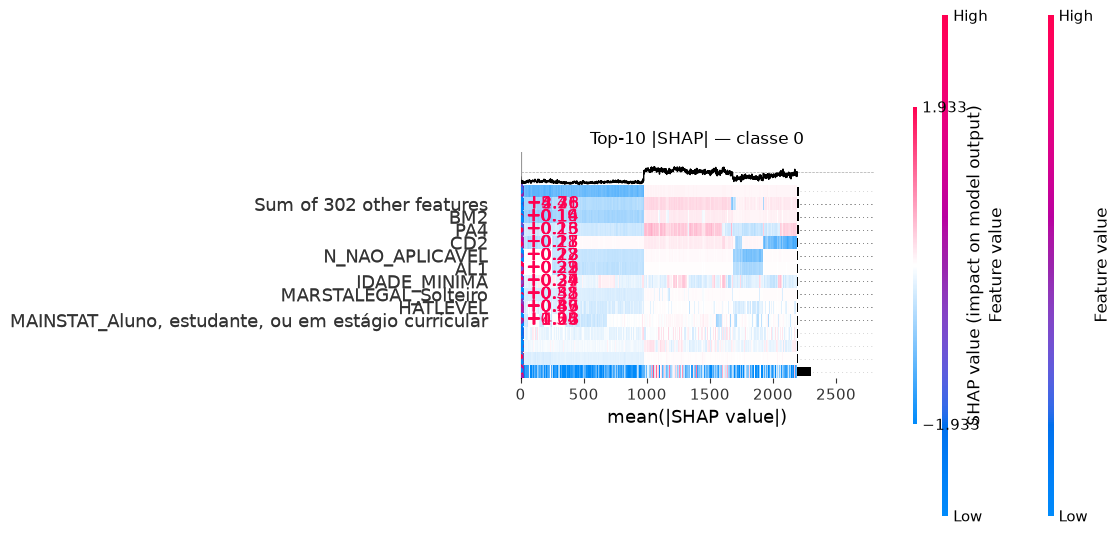

In [7]:
# beeswarm de UMA saída (regra do skill: fatiar output antes de plotar)
CLASSES = {'classe_13': 13, 'classe_1': 1}
for nome, c in CLASSES.items():
    shap.plots.beeswarm(exp[..., c], max_display=15, show=False)
    plt.title(f'Beeswarm — margem bruta da classe {c}')
    fig(f'shap_beeswarm_{nome}')

# heatmap de amostra × feature (padrão PL7) — padrões por amostra na classe 13
shap.plots.heatmap(exp[..., 13], max_display=15, show=False)
plt.title('Heatmap SHAP — classe 13 (linhas ordenadas pelo modelo)')
fig('shap_heatmap_classe13')

# barras por classe (piores 4 + melhor)
piores = [4, 13, 5, 12]
for c in piores + [0]:
    shap.plots.bar(exp[..., c], max_display=10, show=False)
    plt.title(f'Top-10 |SHAP| — classe {c}')
    fig(f'shap_bar_classe{c}')

figura: ../docs/fig_nb14_shap_dep_PC1A.png


figura: ../docs/fig_nb14_shap_dep_MAINSTAT_Aluno, estudante, ou .png


figura: ../docs/fig_nb14_shap_dep_MARSTALEGAL_Solteiro.png


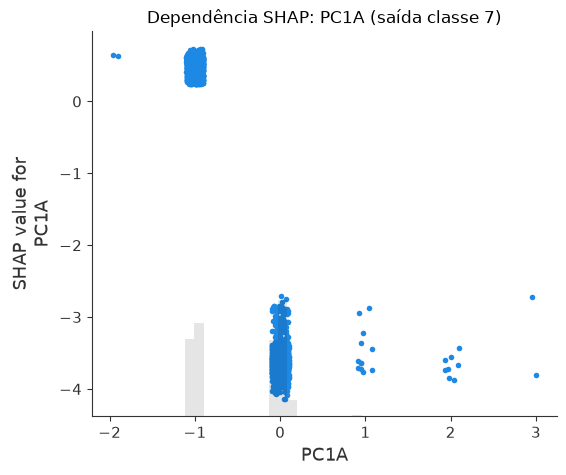

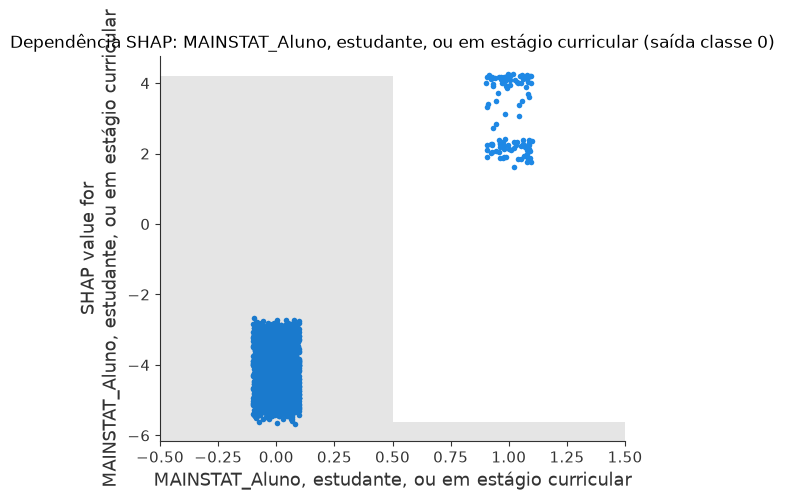

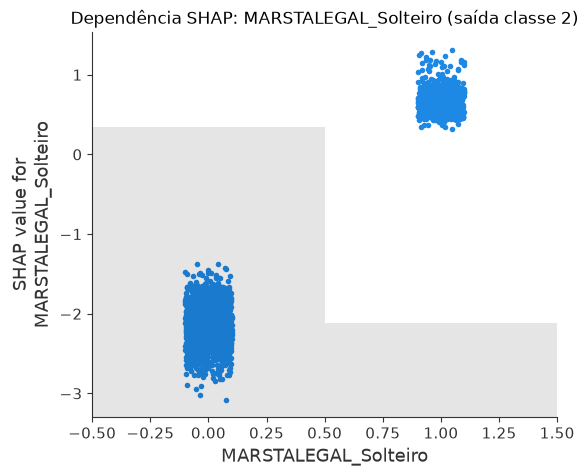

In [8]:
# dependências: feature globalmente top-3 -> saída onde tem mais magnitude
top3 = np.array(cols)[ordem[:3]]
for f in top3:
    fi = cols.index(f)
    c = int(np.abs(exp.values[:, fi, :]).mean(axis=0).argmax())
    shap.plots.scatter(exp[..., c][:, f], show=False)
    plt.title(f'Dependência SHAP: {f} (saída classe {c})')
    fig(f'shap_dep_{f[:30]}')

## 5. Estabilidade: rótulos originais vs relabel (mesmas linhas)

In [9]:
exp_o = shap_do(M0_orig, X_val, 'M0_orig')
g_o = np.abs(exp_o.values).mean(axis=(0, 2))
g_r = np.abs(exp.values).mean(axis=(0, 2))
rho = float(pd.Series(g_o).corr(pd.Series(g_r), method='spearman'))
top10_o = set(np.array(cols)[np.argsort(-g_o)[:10]])
top10_r = set(np.array(cols)[np.argsort(-g_r)[:10]])
jac = len(top10_o & top10_r) / len(top10_o | top10_r)
reg('estabilidade', 'spearman_rank_shap', round(rho, 3), 'orig vs relabel')
reg('estabilidade', 'jaccard_top10', round(jac, 3))
print('top10 orig :', sorted(top10_o))
print('top10 relab:', sorted(top10_r))
del exp_o, M0_orig

M0_orig: shap (2193, 311, 16) | aditividade max|erro| = 1.29e-05
[shap] aditividade_M0_orig: 1.3e-05 base+Σshap == margem bruta
[estabilidade] spearman_rank_shap: 0.977 orig vs relabel
[estabilidade] jaccard_top10: 0.818 
top10 orig : [np.str_('HA1B'), np.str_('HATLEVEL'), np.str_('HH_ACT'), np.str_('HH_INACT'), np.str_('IDADE_MINIMA'), np.str_('MAINSTAT_Aluno, estudante, ou em estágio curricular'), np.str_('MAINSTAT_Reformado, com reforma antecipada ou cessou a atividade'), np.str_('MARSTALEGAL_Solteiro'), np.str_('PC1A'), np.str_('PC1D')]
top10 relab: [np.str_('HATLEVEL'), np.str_('HH_ACT'), np.str_('HH_INACT'), np.str_('IDADE_MINIMA'), np.str_('MAINSTAT_Aluno, estudante, ou em estágio curricular'), np.str_('MAINSTAT_Reformado, com reforma antecipada ou cessou a atividade'), np.str_('MARSTALEGAL_Solteiro'), np.str_('PA7_NAC'), np.str_('PC1A'), np.str_('PC1D')]


## 6. Fronteiras F&H (o que decide a produção, k=4 / k=8 / k=12)

A produção é 15 binários `P(y > k)`. Treinados na fold-0 (rótulos relabel) e
explicados nas mesmas linhas held-out. `k=8` = fronteira dos 55 anos (routing).

bin_k4: shap (2193, 311, 1) | aditividade max|erro| = 8.58e-06
[shap] aditividade_bin_k4: 8.6e-06 base+Σshap == margem bruta


figura: ../docs/fig_nb14_fh_k4_bar.png


bin_k8: shap (2193, 311, 1) | aditividade max|erro| = 6.20e-06
[shap] aditividade_bin_k8: 6.2e-06 base+Σshap == margem bruta


figura: ../docs/fig_nb14_fh_k8_bar.png


bin_k12: shap (2193, 311, 1) | aditividade max|erro| = 7.63e-06
[shap] aditividade_bin_k12: 7.6e-06 base+Σshap == margem bruta


figura: ../docs/fig_nb14_fh_k12_bar.png


figura: ../docs/fig_nb14_fh_k8_beeswarm.png


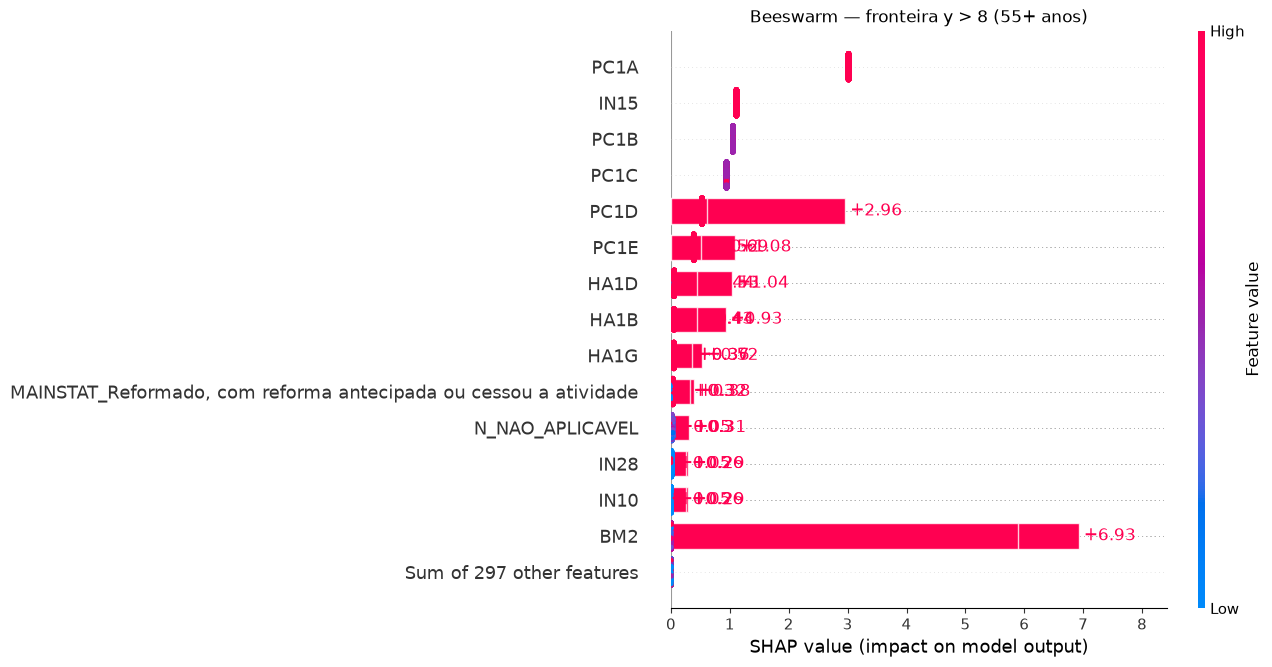

In [10]:
BINS_K = [4, 8, 12]
exp_bins, bin_models = {}, {}
for k in BINS_K:
    m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.5,
        tree_method='hist', random_state=42, n_jobs=-1, eval_metric='logloss')
    m.fit(Xv[b0], (y_lab[b0] > k).astype(int),
          sample_weight=compute_sample_weight('balanced', y_lab[b0]))
    bin_models[k] = m
    ek = shap_do(m, X_val, f'bin_k{k}')
    exp_bins[k] = ek
    shap.plots.bar(ek, max_display=10, show=False)
    plt.title(f'Fronteira y > {k}: top-10 |SHAP|')
    fig(f'fh_k{k}_bar')
shap.plots.beeswarm(exp_bins[8], max_display=15, show=False)
plt.title('Beeswarm — fronteira y > 8 (55+ anos)')
fig('fh_k8_beeswarm')

## 7. Cruzamentos model-agnostic (scikit-learn)

[model_agnostic] spearman_shap_vs_permutacao: 0.468 rank sobre 311 features


figura: ../docs/fig_nb14_permutacao.png


'                                                         feature  perm_mean  perm_std\n                                                        HH_INACT     0.0681    0.0043\n             MAINSTAT_Aluno, estudante, ou em estágio curricular     0.0577    0.0045\n                                                        HATLEVEL     0.0542    0.0075\n                                                         PA7_NAC     0.0341    0.0020\n                                            MARSTALEGAL_Solteiro     0.0298    0.0037\nMAINSTAT_Reformado, com reforma antecipada ou cessou a atividade     0.0272    0.0038\n                                                          HH_ACT     0.0222    0.0037\n                                                    IDADE_MINIMA     0.0191    0.0042\n                                                            PC1E     0.0183    0.0003\n                                                            PC1A     0.0170    0.0067\n                                          

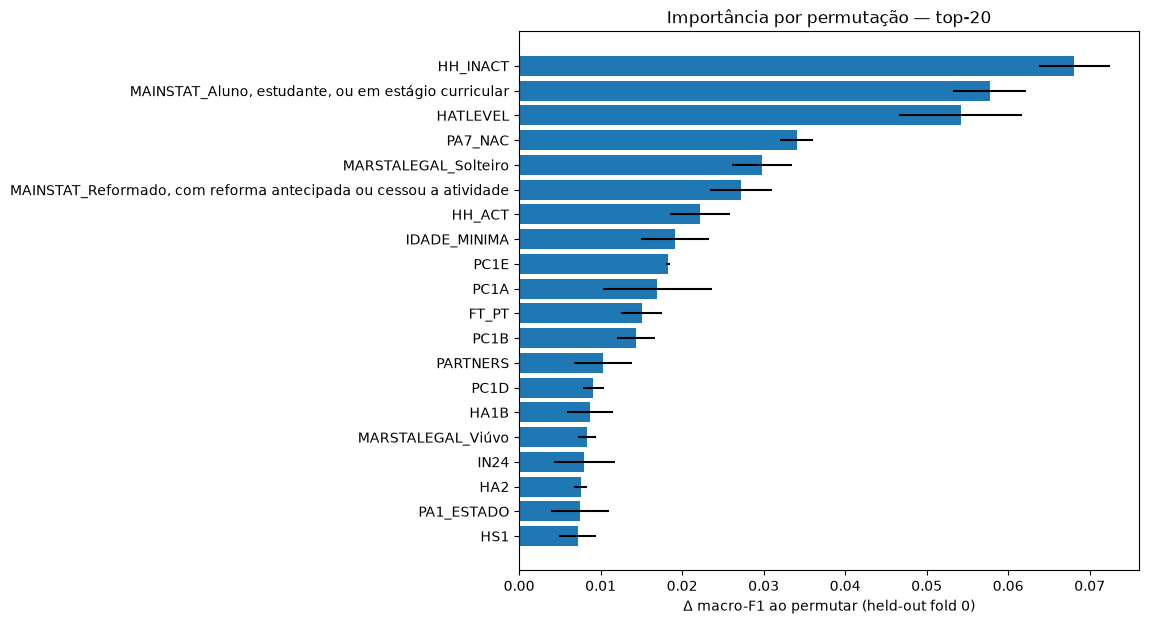

In [11]:
# 7.1 importância por permutação (held-out) e concordância com SHAP
perm = permutation_importance(M0, X_val, y_val, n_repeats=N_REPEATS,
                              scoring='f1_macro', random_state=42, n_jobs=-1)
tab_p = pd.DataFrame({'feature': cols,
                      'perm_mean': perm.importances_mean,
                      'perm_std': perm.importances_std}).sort_values('perm_mean', ascending=False)
tab_p.to_csv(os.path.join(DATA_DIR, 'nb14_permutacao.csv'), index=False)
# alinhamento de índices: Series(g_r) precisa do mesmo índice (nome da feature)!
rho_sp = float(pd.Series(g_r, index=cols).rank().corr(
    tab_p.set_index('feature').reindex(cols)['perm_mean'].rank()))
reg('model_agnostic', 'spearman_shap_vs_permutacao', round(rho_sp, 3), 'rank sobre 311 features')
plt.figure(figsize=(8, 7))
top = tab_p.head(20).iloc[::-1]
plt.barh(top['feature'], top['perm_mean'], xerr=top['perm_std'])
plt.xlabel('Δ macro-F1 ao permutar (held-out fold 0)')
plt.title('Importância por permutação — top-20')
fig('permutacao')
display(tab_p.head(15).round(4).to_string(index=False))

figura: docs/fig_nb14_pdp.png


figura: ../docs/fig_nb14_shap_pdp_fh8_PC1A.png


figura: ../docs/fig_nb14_shap_pdp_fh8_IN15.png


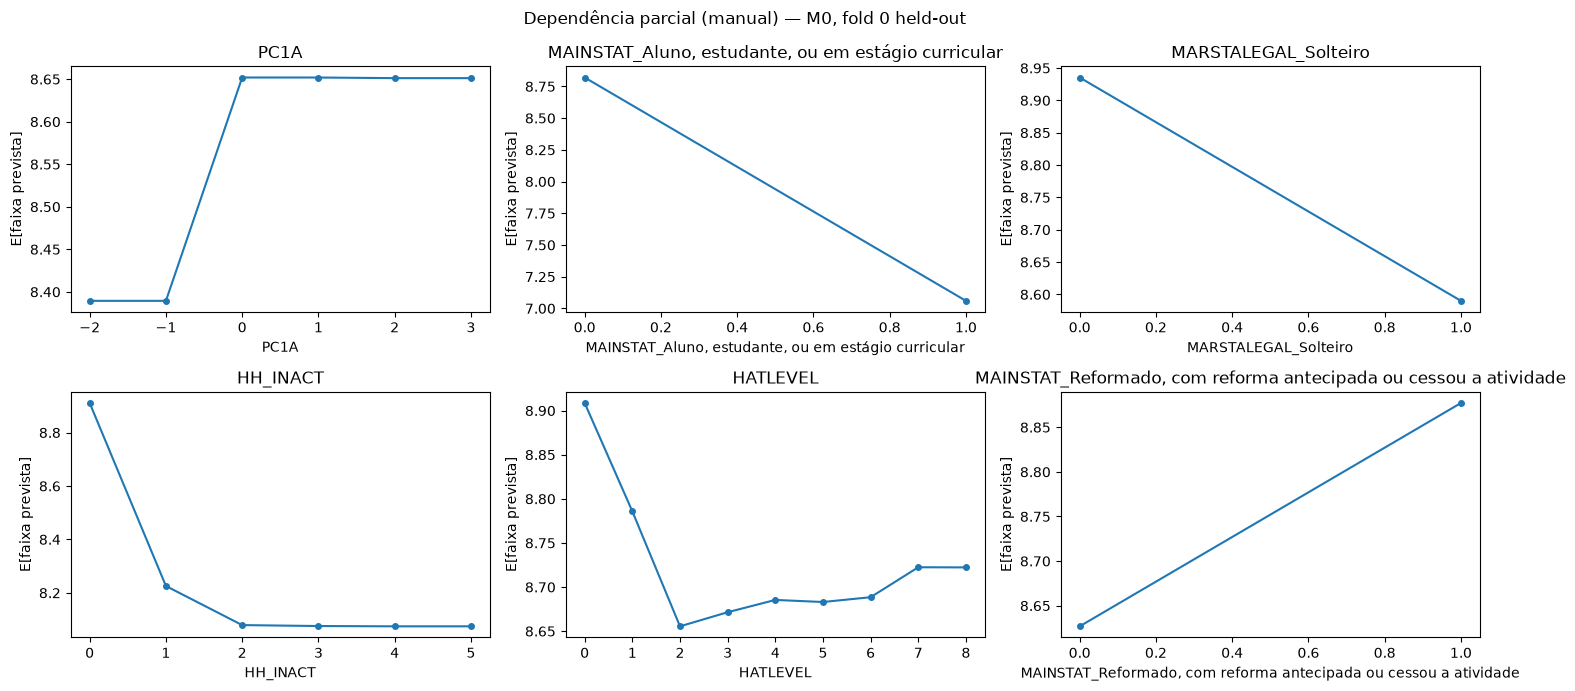

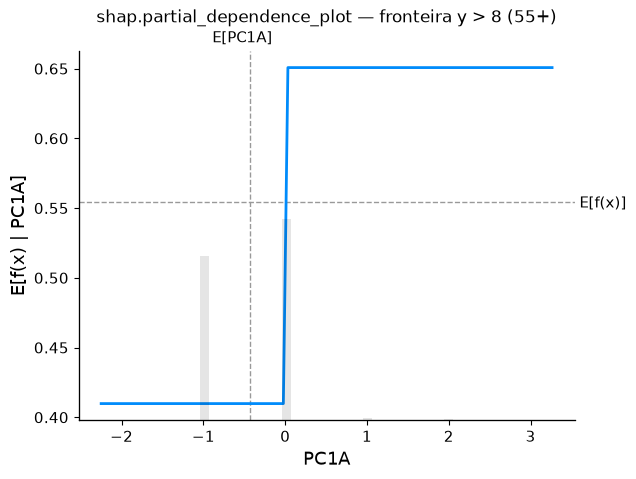

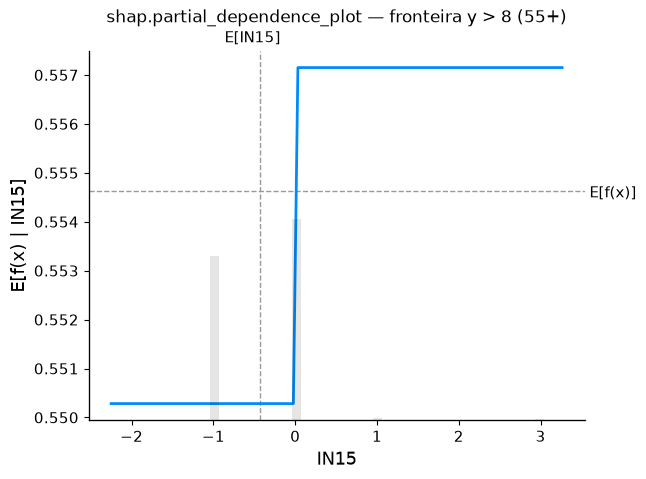

In [12]:
# 7.2 dependência parcial MANUAL (batch predict): o partial_dependence do sklearn
# devolve `average` 2-D (n_grid × k) — o .ravel() anterior casava mal com o grid (1-D)
# e é lento com XGB multiclasse. Curva = E[faixa prevista] sob intervenção na feature.
top6 = list(np.array(cols)[ordem[:6]])
fig_p, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, fname in zip(axes.ravel(), top6):
    fi = cols.index(fname)
    col = X_val[:, fi]
    u = np.unique(col)
    xs = u if len(u) <= 20 else np.linspace(np.percentile(col, 1), np.percentile(col, 99), 20)
    ys = []
    for xv_ in xs:
        Xq = X_val.copy(); Xq[:, fi] = xv_
        Pq = M0.predict_proba(Xq)
        ys.append(float((Pq * np.arange(K)).sum(axis=1).mean()))
    ax.plot(xs, ys, 'o-', ms=4)
    ax.set_title(fname); ax.set_xlabel(fname); ax.set_ylabel('E[faixa prevista]')
fig_p.suptitle('Dependência parcial (manual) — M0, fold 0 held-out')
plt.tight_layout()
fig_p.savefig(os.path.join(FIG_DIR, 'fig_nb14_pdp.png'), bbox_inches='tight')
print('figura: docs/fig_nb14_pdp.png')

# 7.3 PDP no estilo do PL7 (shap.partial_dependence_plot) sobre a fronteira 55+
for f in list(np.array(cols)[np.argsort(-np.abs(exp_bins[8].values).mean(axis=0))[:2]]):
    shap.partial_dependence_plot(
        f, (lambda Xr: bin_models[8].predict_proba(Xr)[:, 1]), X_val,
        feature_names=cols, ice=False,
        model_expected_value=True, feature_expected_value=True, show=False)
    plt.title('shap.partial_dependence_plot — fronteira y > 8 (55+)')
    fig(f'shap_pdp_fh8_{f[:28]}')

[surrogato] fidelidade_cv: 0.4848 árvore depth-4 reproduz E26 (5-fold)
[surrogato] macro_f1_vs_verdade: 0.3206 (E26 = 0.5365)
|--- PC1A <= -0.50
|   |--- MARSTALEGAL_Solteiro <= 0.50
|   |   |--- HHNBPERS_0_13_COD <= 0.50
|   |   |   |--- PA5 <= 2.50
|   |   |   |   |--- class: 8
|   |   |   |--- PA5 >  2.50
|   |   |   |   |--- class: 7
|   |   |--- HHNBPERS_0_13_COD >  0.50
|   |   |   |--- PA7_NAC <= 3.50
|   |   |   |   |--- class: 6
|   |   |   |--- PA7_NAC >  3.50
|   |   |   |   |--- class: 5
|   |--- MARSTALEGAL_Solteiro >  0.50
|   |   |--- MAINSTAT_Aluno, estudante, ou em estágio curricular <= 0.50
|   |   |   |--- HHTYPE_Casal com pelo menos um filho < 25 anos <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- HHTYPE_Casal com pelo menos um filho < 25 anos >  0.50
|   |   |   |   |--- class: 2
|   |   |--- MAINSTAT_Aluno, estudante, ou em estágio curricular >  0.50
|   |   |   |--- HATLEVEL <= 2.50
|   |   |   |   |--- class: 0
|   |   |   |--- HATLEVEL >  2.50
|   |   |

Background dataset has 220 samples but max_samples=219. Subsampling to 219 samples for SHAP value computation. To use all samples, set max_samples=220 when initializing the masker.


[contraste] logreg_val_macro_f1: 0.4636 vs M0 acima (unidades diferentes)


[contraste] spearman_rank_lr_vs_arvore: 0.81 só ranks: unidades de SHAP não são comparáveis entre modelos


figura: ../docs/fig_nb14_shap_bar_logreg.png


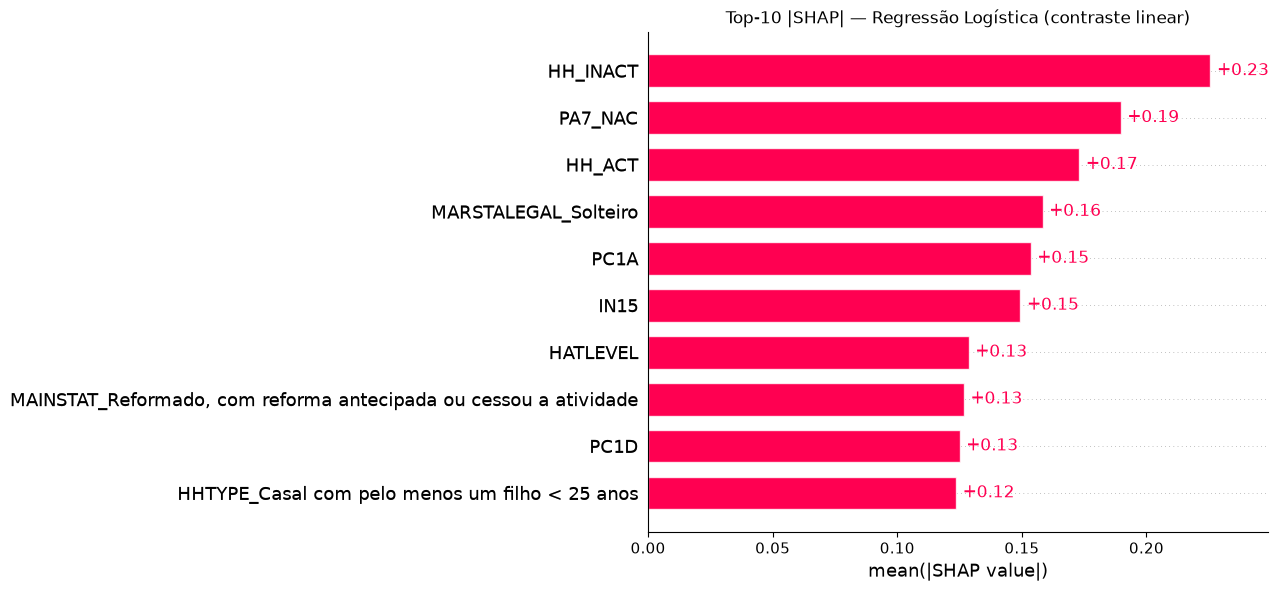

In [13]:
# 7.3 surrogato: até que ponto uma árvore rasa reproduce E26?
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(Xv, pred_e26)
fid = float((dt.predict(Xv) == pred_e26).mean())
fids = []
for a, b in FOLDS:
    dtc = DecisionTreeClassifier(max_depth=4, random_state=42)
    dtc.fit(Xv[a], pred_e26[a])
    fids.append(float((dtc.predict(Xv[b]) == pred_e26[b]).mean()))
f1_dt = f1_score(y, dt.predict(Xv), average='macro')
reg('surrogato', 'fidelidade_cv', round(float(np.mean(fids)), 4),
    'árvore depth-4 reproduz E26 (5-fold)')
reg('surrogato', 'macro_f1_vs_verdade', round(f1_dt, 4), f'(E26 = 0.5365)')
print(export_text(dt, feature_names=list(cols), max_depth=3))

# 7.5 contraste linear (PL7): mesma fold, mesmas linhas — LogReg + LinearExplainer
mu, sd = Xv[b0].mean(0), Xv[b0].std(0) + 1e-9
Xs = (Xv - mu) / sd
lr = LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000, random_state=42)
lr.fit(Xs[b0], y_lab[b0])
f1_lr = f1_score(y_val, lr.predict(Xs[v0]), average='macro')
reg('contraste', 'logreg_val_macro_f1', round(f1_lr, 4), 'vs M0 acima (unidades diferentes)')
expl_lr = shap.LinearExplainer(lr, shap.maskers.Independent(Xs[b0][::40], max_samples=219))
sv_lr = expl_lr(Xs[v0]).values
if isinstance(sv_lr, list):
    sv_lr = np.stack(sv_lr, axis=-1)
sv_lr = np.asarray(sv_lr)
if sv_lr.ndim == 2:
    sv_lr = sv_lr[:, :, None]
g_lr = np.abs(sv_lr).mean(axis=(0, 2))
rho_lr = float(pd.Series(g_lr).rank().corr(pd.Series(g_r).rank()))
reg('contraste', 'spearman_rank_lr_vs_arvore', round(rho_lr, 3),
    'só ranks: unidades de SHAP não são comparáveis entre modelos')
ord_lr = np.argsort(-g_lr)[:10]
shap.plots.bar(shap.Explanation(values=np.abs(sv_lr[:, ord_lr, :]).mean(axis=2),
                                feature_names=np.array(cols)[ord_lr]),
               max_display=10, show=False)
plt.title('Top-10 |SHAP| — Regressão Logística (contraste linear)')
fig('shap_bar_logreg')

## 8. Perfis por classe e fatias de erro (pandas)

figura: ../docs/fig_nb14_perfis_classe.png


'           PC1A  MAINSTAT_Aluno, estudante, ou em estágio curricular  MARSTALEGAL_Solteiro  HH_INACT  HATLEVEL  MAINSTAT_Reformado, com reforma antecipada ou cessou a atividade  PA7_NAC  IDADE_MINIMA\nAGE_RANGE                                                                                                                                                                                              \n0         -1.00                                                 0.99                  0.99      1.20      1.81                                                              0.00     2.18         15.10\n1         -1.00                                                 0.76                  0.98      1.39      2.67                                                              0.00     1.76         15.41\n2         -1.00                                                 0.39                  0.97      1.02      3.48                                                              0.00     1.82         1

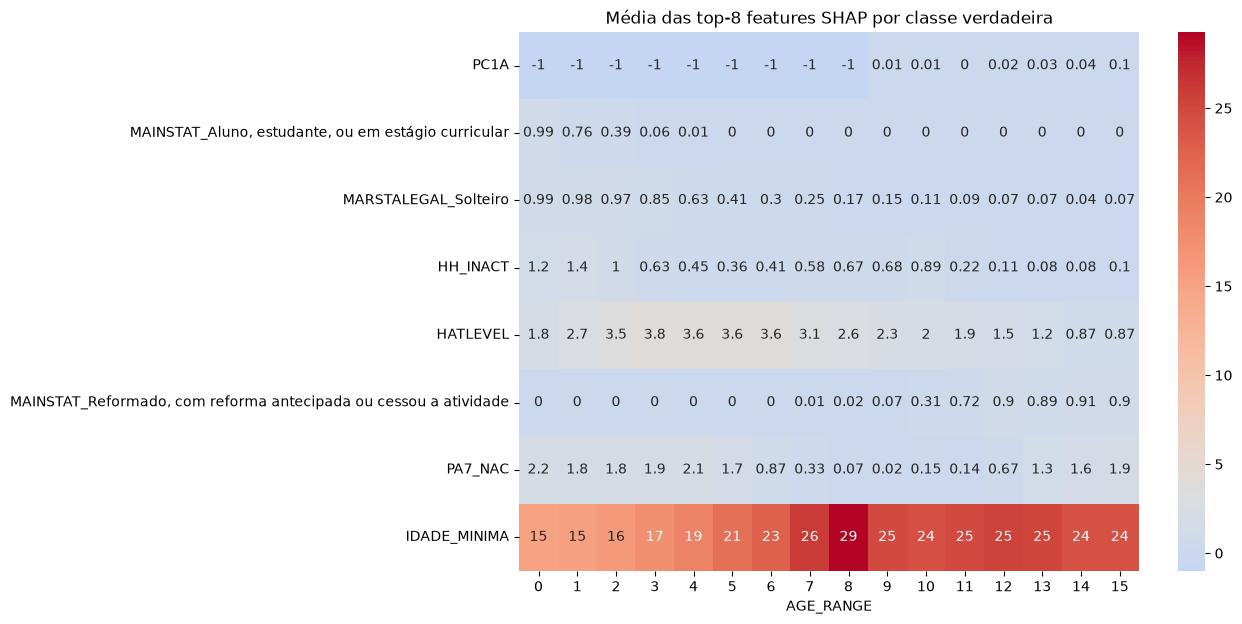

In [14]:
top8 = list(np.array(cols)[ordem[:8]])
perfil = tr.assign(pred=pred_e26).groupby(TARGET)[top8].mean().round(2)
plt.figure(figsize=(10, 7))
sns.heatmap(perfil.T, annot=True, cmap='coolwarm', center=perfil.mean().mean())
plt.title('Média das top-8 features SHAP por classe verdadeira')
fig('perfis_classe')
display(perfil.to_string())

In [15]:
# fatia de erro: erros >= 2 faixas vs corretos — diferenças padronizadas
correto = err == 0; grave = err >= 2
mu_c, mu_g = Xv[correto].mean(0), Xv[grave].mean(0)
sd = Xv.std(0) + 1e-9
z = (mu_g - mu_c) / sd
ordz = np.argsort(-np.abs(z))[:15]
tab_z = pd.DataFrame({'feature': np.array(cols)[ordz],
                      'media_correto': mu_c[ordz].round(2),
                      'media_erro_ge2': mu_g[ordz].round(2),
                      'z': z[ordz].round(2)})
display(tab_z.to_string(index=False))
tab_z.to_csv(os.path.join(DATA_DIR, 'nb14_fatia_erro.csv'), index=False)

# quota de routing na importância total (declaração para o relatório)
def tag(c):
    if c.startswith(('PC1', 'HA1')) or c in ('IN15', 'IN11'): return 'routing_55+'
    if c.startswith(('IN5', 'MAINSTAT', 'JOBSTAT', 'LOCNACE', 'JOBISCO')): return 'routing_trabalho'
    if c.startswith(('IN16', 'IN17', 'IN21', 'IN22', 'IN24', 'IN25', 'IN26')): return 'routing_reprodutivo'
    if c in ('IN1', 'IN2', 'IN3', 'IN4') or c.startswith(('IN1_', 'IN2_', 'IN3_', 'IN4_')): return 'routing_migracao'
    if c.startswith('HATLEVEL'): return 'educacao'
    return 'outro'
tags = pd.Series(cols).map(tag)
quota = float(g_r[[i for i, t in enumerate(tags) if t.startswith('routing')]].sum() / g_r.sum())
reg('routing', 'quota_shap_routing', round(quota, 3),
    'soma |SHAP| dos blocos de routing / total (M0 relabel)')
print(tags.value_counts().to_string())

'                                                         feature  media_correto  media_erro_ge2     z\n                                                            IN24           1.46           -0.20 -0.28\n                                                 N_NAO_APLICAVEL          52.45           54.64  0.26\n             MAINSTAT_Aluno, estudante, ou em estágio curricular           0.06            0.01 -0.24\n                                                          HH_ACT           0.98            0.78 -0.21\n                                                        HH_INACT           0.53            0.37 -0.21\n                                          IN22_Está na menopausa           0.04            0.01 -0.20\nMAINSTAT_Reformado, com reforma antecipada ou cessou a atividade           0.32            0.42  0.20\n                                                             NT3          -0.75           -0.87 -0.20\n                                                            CD1K        

[routing] quota_shap_routing: 0.362 soma |SHAP| dos blocos de routing / total (M0 relabel)
outro                  215
routing_trabalho        48
routing_reprodutivo     26
routing_55+             14
routing_migracao         7
educacao                 1


## 9. Explicações locais (regra de seleção documentada)

Quatro casos, todos na validação held-out: (a) classe rara 1 correta de maior
confiança; (b) maior erro |pred−true|; (c) erro de 1 faixa na classe 13;
(d) linha onde a correção FAIXA_MINIMA mudou a previsão (ou, na ausência,
caso correto de menor margem). Saída explicada: **classe verdadeira** (erros) ou
**classe prevista** (corretos), em margem bruta.

In [16]:
sel = []
def add(rot, i, saida):
    sel.append((rot, int(i), int(saida)))

cand1 = np.where((y_val == 1) & (pred_e26[v0] == 1))[0]
if len(cand1):
    i = cand1[np.argmax(pmax[v0][cand1])]; add('a_classe1_correto', i, 1)
i = int(np.argmax(np.abs(pred_e26[v0] - y_val))); add('b_maior_erro', i, int(y_val[i]))
c13 = np.where((y_val == 13) & (np.abs(pred_e26[v0] - y_val) == 1))[0]
if len(c13):
    add('c_erro1_faixa_classe13', c13[0], 13)
flip = np.where(pred_e26[v0] != pred_raw[v0])[0]
if len(flip):
    add('d_correcao_faixa_minima', flip[0], int(y_val[flip[0]]))
else:
    certos = np.where(pred_e26[v0] == y_val)[0]
    add('d_menor_margem_correto', certos[np.argmin(pmax[v0][certos])], int(y_val[certos[np.argmin(pmax[v0][certos])]]))

for rot, i_local, saida in sel:
    shap.plots.waterfall(exp[..., saida][i_local], max_display=12, show=False)
    plt.title(f'{rot}: y={y_val[i_local]} prev={pred_e26[v0][i_local]} → saída classe {saida}')
    fig(f'local_{rot}')
    print(rot, '| idx_val', i_local, '| y', y_val[i_local], '| prev', pred_e26[v0][i_local])

figura: ../docs/fig_nb14_local_a_classe1_correto.png
a_classe1_correto | idx_val 743 | y 1 | prev 1


figura: ../docs/fig_nb14_local_b_maior_erro.png
b_maior_erro | idx_val 79 | y 14 | prev 8


figura: ../docs/fig_nb14_local_c_erro1_faixa_classe13.png
c_erro1_faixa_classe13 | idx_val 13 | y 13 | prev 12


figura: ../docs/fig_nb14_local_d_correcao_faixa_minima.png
d_correcao_faixa_minima | idx_val 292 | y 10 | prev 10


## 10. Resultados e limitações

In [17]:
pd.DataFrame(RES).to_csv(os.path.join(DATA_DIR, 'nb14_resultados.csv'), index=False)
tab_glob.head(30).assign(perm=tab_glob['feature'].map(
    tab_p.set_index('feature')['perm_mean']),
    tag=tab_glob['feature'].map(tag)).to_csv(
    os.path.join(DATA_DIR, 'nb14_shap_global.csv'), index=False)
print(pd.DataFrame(RES).to_string(index=False))
print("""
LIMITAÇÕES (para o relatório):
- SHAP = descrição do comportamento do modelo sob masking tree-path-dependent; não causal.
- Unidade = margem bruta (logit), não probabilidade; magnitudes não são comparáveis entre
  modelos com outputs diferentes, apenas dentro do mesmo modelo/linhas/saída.
- Features correlacionadas (routing 55+, blocos de idade) dividem atribuições — a quota de
  routing é um piso, não uma medição exata de quanto sinal é 'questionário vs biologia'.
- Correlações/associações do §8 são exploratórias (sem teste confirmatório).
- Surrogato: fidelidade medida in-sample + CV; réguas de árvore são aproximações, não regras
  causais do modelo real.""")

         secao                     metrica   valor                                                         nota
      sanidade            E26_mean_fold_f1  0.5364                                             cache NB13 rel15
          erro                    macro_f1  0.5365                                                             
          erro              off_by_one_pct    76.0                                   % dos erros são de 1 faixa
          erro                  erro_ge2_n    1229                                                             
    calibracao                  ECE_10bins  0.0953                                                             
      correcao            linhas_alteradas      19                                     ajudou 10 / prejudicou 0
     auditoria      cv_relabel_multiclasse  0.5341            +/- 0.0065 | base original 0.4777 → delta +0.0564
          shap      aditividade_M0_relabel 1.3e-05                                   base+Σshap == marge